# **Exercise 1: Regression Task** - *Laptop Price Prediction*

# **Importing the Libraries**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
data = pd.read_csv("/kaggle/input/datasets/juyams/laptop-price/Laptop_price.csv")
print("Loaded:", "/kaggle/input/datasets/juyams/laptop-price/Laptop_price.csv")
print("Rows:", len(data), "| Columns:", len(data.columns))

Loaded: /kaggle/input/datasets/juyams/laptop-price/Laptop_price.csv
Rows: 1000 | Columns: 7


# **Exploring the Dataset**

In [3]:
data

,Brand,Processor_Speed,RAM_Size,Storage_Capacity,Screen_Size,Weight,Price
0,Asus,3.830296,16,512,11.185147,2.641094,17395.093065
1,Acer,2.912833,4,1000,11.311372,3.260012,31607.605919
2,Lenovo,3.241627,4,256,11.853023,2.029061,9291.023542
3,Acer,3.806248,16,512,12.280360,4.573865,17436.728334
4,Acer,3.268097,32,1000,14.990877,4.193472,32917.990718
...,...,...,...,...,...,...,...
995,HP,3.343584,4,1000,12.587095,3.162399,31593.668017
996,Dell,2.780555,8,256,12.679356,3.750265,9149.521832
997,Dell,3.200569,4,512,12.666315,3.392612,16552.404779
998,Asus,1.604182,8,256,11.215581,3.857613,9407.473459


In [4]:
data.info

<bound method DataFrame.info of       Brand  Processor_Speed  RAM_Size  Storage_Capacity  Screen_Size  \
0      Asus         3.830296        16               512    11.185147   
1      Acer         2.912833         4              1000    11.311372   
2    Lenovo         3.241627         4               256    11.853023   
3      Acer         3.806248        16               512    12.280360   
4      Acer         3.268097        32              1000    14.990877   
..      ...              ...       ...               ...          ...   
995      HP         3.343584         4              1000    12.587095   
996    Dell         2.780555         8               256    12.679356   
997    Dell         3.200569         4               512    12.666315   
998    Asus         1.604182         8               256    11.215581   
999  Lenovo         1.711980         4               256    16.561498   

       Weight         Price  
0    2.641094  17395.093065  
1    3.260012  31607.605919  
2

In [5]:
data.head()

,Brand,Processor_Speed,RAM_Size,Storage_Capacity,Screen_Size,Weight,Price
0,Asus,3.830296,16,512,11.185147,2.641094,17395.093065
1,Acer,2.912833,4,1000,11.311372,3.260012,31607.605919
2,Lenovo,3.241627,4,256,11.853023,2.029061,9291.023542
3,Acer,3.806248,16,512,12.280360,4.573865,17436.728334
4,Acer,3.268097,32,1000,14.990877,4.193472,32917.990718


In [6]:
data.tail()

,Brand,Processor_Speed,RAM_Size,Storage_Capacity,Screen_Size,Weight,Price
995,HP,3.343584,4,1000,12.587095,3.162399,31593.668017
996,Dell,2.780555,8,256,12.679356,3.750265,9149.521832
997,Dell,3.200569,4,512,12.666315,3.392612,16552.404779
998,Asus,1.604182,8,256,11.215581,3.857613,9407.473459
999,Lenovo,1.711980,4,256,16.561498,3.440883,8807.696702


In [7]:
data.shape

(1000, 7)

# **Selection X and Y**

In [8]:
X = data[['Processor_Speed', 'RAM_Size', 'Storage_Capacity', 'Screen_Size', 'Weight']]

In [9]:
X.head()

,Processor_Speed,RAM_Size,Storage_Capacity,Screen_Size,Weight
0,3.830296,16,512,11.185147,2.641094
1,2.912833,4,1000,11.311372,3.260012
2,3.241627,4,256,11.853023,2.029061
3,3.806248,16,512,12.280360,4.573865
4,3.268097,32,1000,14.990877,4.193472


In [10]:
y = data['Price']

In [11]:
y.head()

0    17395.093065
1    31607.605919
2     9291.023542
3    17436.728334
4    32917.990718
Name: Price, dtype: float64

# **Splitting the Data**

In [12]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [13]:
X_train.shape

(800, 5)

In [14]:
X_test.shape

(200, 5)

In [15]:
y_train.head()

29     31747.604606
535    17515.915181
695    17073.491966
557    18399.777107
836    17787.920193
Name: Price, dtype: float64

In [16]:
X_train.head()

,Processor_Speed,RAM_Size,Storage_Capacity,Screen_Size,Weight
29,3.799639,8,1000,12.853007,2.151678
535,3.298004,16,512,15.144079,2.587267
695,2.433129,4,512,15.046398,2.264456
557,3.313144,32,512,12.836309,2.376126
836,3.162279,16,512,14.701664,2.943887


# **Confirming the Split Sizes**

In [17]:
print("Training laptops:", len(X_train))
print("Training prices:", len(y_train))
print("Test laptops:", len(X_test))
print("Test prices:", len(y_test))

Training laptops: 800
Training prices: 800
Test laptops: 200
Test prices: 200


# **Building & Training the Model**

In [18]:
model = LinearRegression()

In [19]:
model.fit(X_train, y_train)

LinearRegression()

# **Model Testing**

In [20]:
price_prediction = model.predict(X_test)

In [21]:
price_prediction[:10]

array([10749.63777067, 31554.70782635,  9642.10425199,  9235.48855959,
       32023.18899099, 31640.31802205, 10317.76535524, 16947.76854654,
       18498.97401896, 32359.923062  ])

In [22]:
comparison = pd.DataFrame({
    "Original row": y_test.index,
    "Actual price": y_test.to_numpy(),
    "Predicted price": price_prediction
})
comparison["Error"] = comparison["Actual price"] - comparison["Predicted price"]
comparison["Absolute error"] = comparison["Error"].abs()
display(comparison.head(10).round(2))

,Original row,Actual price,Predicted price,Error,Absolute error
0,521,10900.50,10749.64,150.86,150.86
1,737,31727.52,31554.71,172.81,172.81
2,740,9636.02,9642.10,-6.08,6.08
3,660,9412.60,9235.49,177.11,177.11
4,411,31641.11,32023.19,-382.08,382.08
5,678,31832.49,31640.32,192.17,192.17
6,626,10438.45,10317.77,120.69,120.69
7,513,17205.21,16947.77,257.44,257.44
8,859,18743.57,18498.97,244.60,244.60
9,136,32342.71,32359.92,-17.22,17.22


In [23]:
mse = mean_squared_error(y_test, price_prediction)
print(f"Test MSE: {mse:,.2f} squared price units")

Test MSE: 32,031.54 squared price units


In [24]:
mae = mean_absolute_error(y_test, price_prediction)
print(f"Test MAE: {mse:,.2f} average absolute price units")

Test MAE: 32,031.54 average absolute price units


In [25]:
r2 = r2_score(y_test, price_prediction)
print(f"Test r2: {mse:,.2f} price units")

Test r2: 32,031.54 price units


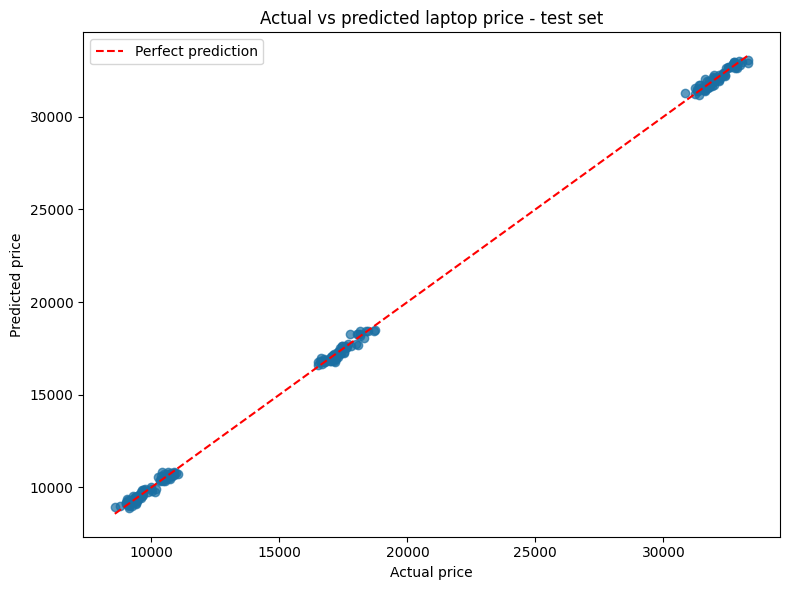

In [26]:
plt.figure(figsize=(8, 6))
plt.scatter(y_test, price_prediction, alpha=0.7, color="#1A6FA3")

lowest_price = min(y_test.min(), price_prediction.min())
highest_price = max(y_test.max(), price_prediction.max())
plt.plot(
    [lowest_price, highest_price], [lowest_price, highest_price],
    "r--", label="Perfect prediction"
)

plt.xlabel("Actual price")
plt.ylabel("Predicted price")
plt.title("Actual vs predicted laptop price - test set")
plt.ticklabel_format(style="plain", axis="both")
plt.legend()
plt.tight_layout()
plt.show()

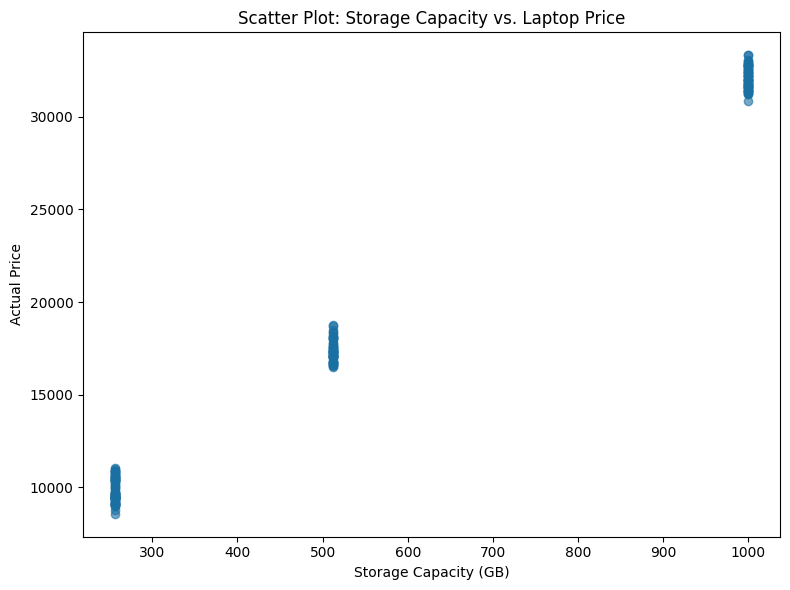

In [27]:
plt.figure(figsize=(8, 6))
plt.scatter(X_test["Storage_Capacity"], y_test, alpha=0.6, color="#1A6FA3")
plt.xlabel("Storage Capacity (GB)")
plt.ylabel("Actual Price")
plt.title("Scatter Plot: Storage Capacity vs. Laptop Price")
plt.tight_layout()
plt.show()

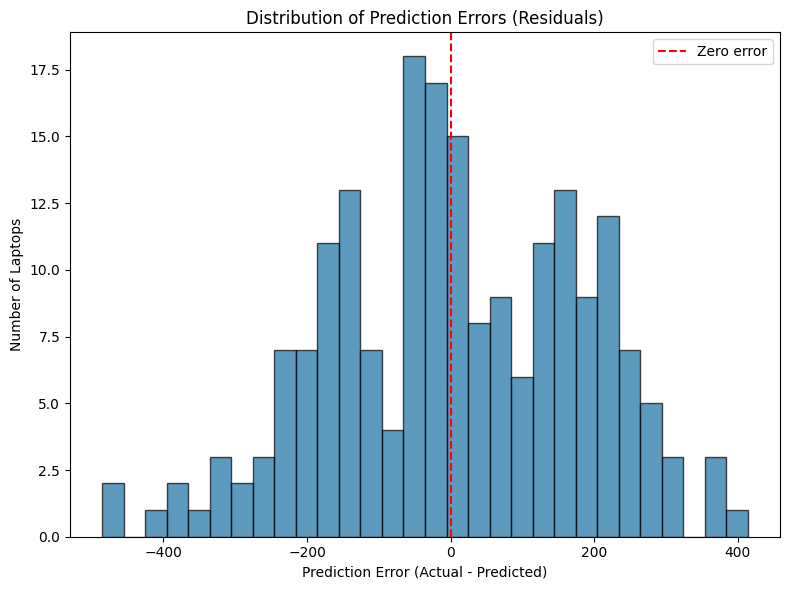

In [28]:
errors = y_test - price_prediction
plt.figure(figsize=(8, 6))
plt.hist(errors, bins=30, color="#1A6FA3", edgecolor="black", alpha=0.7)
plt.axvline(0, color="r", linestyle="--", label="Zero error")
plt.xlabel("Prediction Error (Actual - Predicted)")
plt.ylabel("Number of Laptops")
plt.title("Distribution of Prediction Errors (Residuals)")
plt.legend()
plt.tight_layout()
plt.show()